# Глубина и ширина MLP

Сравним пять MLP разной глубины и ширины на функции `sin(3x) + 0.3x` с шумом. Проведём обучение с двумя значениями learning rate и сравним ошибки на train и validation.


## Ход работы

Генерируем точки функции `sin(3x) + 0.3x` с шумом и делим их на train и validation. Задаём пять архитектур: Small, Medium, Wide, Deep и Very Deep. Для каждой считаем число обучаемых параметров, чтобы сопоставить размер сети с полученным качеством.

Сначала обучаем все архитектуры с learning rate 0.01, затем повторяем сравнение с 0.001. В каждом опыте сохраняем ошибки и строим кривые validation. Сопоставляем train и validation MSE: это помогает различить хорошую подгонку обучающих данных и качество на отложенных точках.


### Фиксируем случайное состояние

Задаём генераторы случайных чисел для одинакового шума и воспроизводимых разбиений. При сравнении сетей важно не менять данные вместе с архитектурой.

In [1]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)


### Готовим задачу аппроксимации

Создаём точки на отрезке от −3 до 3, добавляем шум к функции `sin(3x) + 0.3x` и разделяем точки на обучение и валидацию. Это регрессия: на выходе должно быть одно число.

In [2]:
x=torch.linspace(-3,3,200).reshape(-1,1)
y=torch.sin(3*x)+0.3*x+0.15*torch.randn_like(x)
indices=torch.randperm(200); tr,va=indices[:160],indices[160:]


### Определяем пять архитектур

Small и Medium отличаются числом нейронов, Wide ещё шире, а Deep и Very Deep имеют больше скрытых слоёв. При подсчёте параметров учитываются и веса матриц, и смещения нейронов.

In [3]:
architectures={"Small":[1,4,1],"Medium":[1,16,1],"Wide":[1,64,1],"Deep":[1,16,16,1],"Very Deep":[1,32,32,32,1]}


### Эксперимент A: learning rate 0.01

Обучаем все пять сетей с одним размером шага и одинаковым бюджетом эпох. Сравниваем отдельно Train MSE и Validation MSE: низкая ошибка на обучении не гарантирует успешную работу на новых точках.

Обучение lr = 0.01


Small 13 0.18207 0.14838


Medium 49 0.02001 0.02735


Wide 193 0.02283 0.0289


Deep 321 0.01872 0.02552


Very Deep 2209 0.01813 0.02634


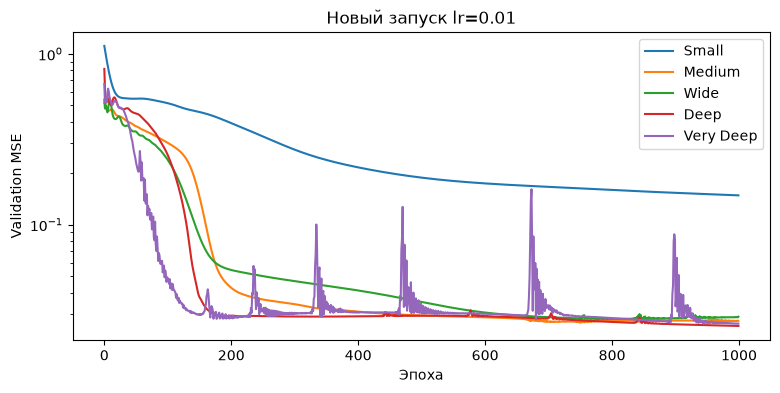

In [4]:
lr = 0.01
print("Обучение lr =",lr)
plt.figure(figsize=(9,4))
for name,widths in architectures.items():
    torch.manual_seed(42)
    layers=[]
    for i in range(len(widths)-1):
        layers.append(nn.Linear(widths[i],widths[i+1]))
        if i<len(widths)-2: layers.append(nn.Tanh())
    model=nn.Sequential(*layers)
    optimizer=torch.optim.Adam(model.parameters(),lr=lr)
    history=[]
    for epoch in range(1000):
        optimizer.zero_grad(); loss=nn.functional.mse_loss(model(x[tr]),y[tr]); loss.backward(); optimizer.step()
        with torch.no_grad(): history.append(nn.functional.mse_loss(model(x[va]),y[va]).item())
    with torch.no_grad(): train=nn.functional.mse_loss(model(x[tr]),y[tr]).item()
    print(name,sum(p.numel() for p in model.parameters()),round(train,5),round(history[-1],5))
    plt.plot(history,label=name)
plt.yscale('log'); plt.title(f'Обучение lr={lr}'); plt.xlabel('Эпоха'); plt.ylabel('Validation MSE'); plt.legend(); plt.show()


**Вывод по опыту.** Меньшая train MSE при большей validation MSE означает, что дополнительная гибкость не дала выигрыша на этом разбиении. Разницу двух learning rate следует оценивать при одинаковом бюджете.

### Эксперимент B: learning rate 0.001

Меняем только скорость обучения и повторяем сравнение. При меньшем шаге модель может сходиться медленнее; если эпох недостаточно, это нельзя трактовать как доказательство слабой архитектуры.

Обучение lr = 0.001


Small 13 0.5493 0.4874


Medium 49 0.14622 0.12896


Wide 193 0.08219 0.07326


Deep 321 0.04477 0.04092


Very Deep 2209 0.01976 0.02805


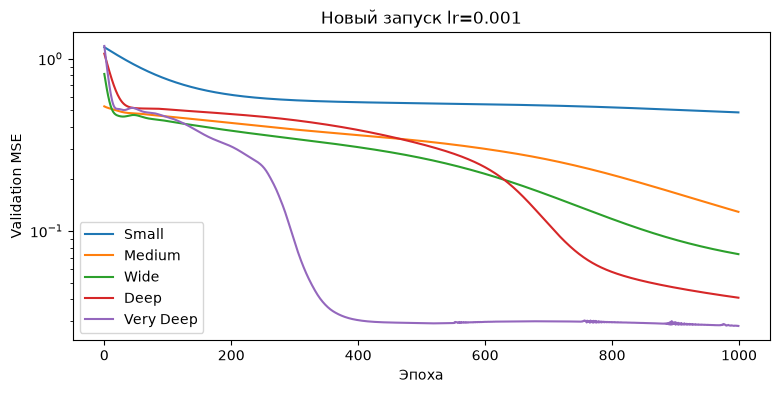

In [5]:
lr = 0.001
print("Обучение lr =",lr)
plt.figure(figsize=(9,4))
for name,widths in architectures.items():
    torch.manual_seed(42)
    layers=[]
    for i in range(len(widths)-1):
        layers.append(nn.Linear(widths[i],widths[i+1]))
        if i<len(widths)-2: layers.append(nn.Tanh())
    model=nn.Sequential(*layers)
    optimizer=torch.optim.Adam(model.parameters(),lr=lr)
    history=[]
    for epoch in range(1000):
        optimizer.zero_grad(); loss=nn.functional.mse_loss(model(x[tr]),y[tr]); loss.backward(); optimizer.step()
        with torch.no_grad(): history.append(nn.functional.mse_loss(model(x[va]),y[va]).item())
    with torch.no_grad(): train=nn.functional.mse_loss(model(x[tr]),y[tr]).item()
    print(name,sum(p.numel() for p in model.parameters()),round(train,5),round(history[-1],5))
    plt.plot(history,label=name)
plt.yscale('log'); plt.title(f'Обучение lr={lr}'); plt.xlabel('Эпоха'); plt.ylabel('Validation MSE'); plt.legend(); plt.show()


**Вывод по опыту.** Меньшая train MSE при большей validation MSE означает, что дополнительная гибкость не дала выигрыша на этом разбиении. Разницу двух learning rate следует оценивать при одинаковом бюджете.

## Выводы

Увеличение глубины и ширины не гарантирует меньшую ошибку на validation. Результат зависит и от learning rate: при одинаковом числе эпох разные сети успевают обучиться по-разному.


## Полный код


Обучение lr = 0.01


Small 13 0.18207 0.14838


Medium 49 0.02001 0.02735


Wide 193 0.02283 0.0289


Deep 321 0.01872 0.02552


Very Deep 2209 0.01813 0.02634


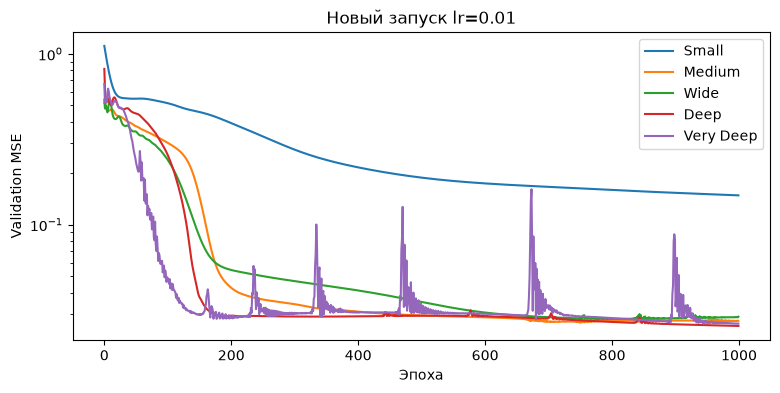

Обучение lr = 0.001


Small 13 0.5493 0.4874


Medium 49 0.14622 0.12896


Wide 193 0.08219 0.07326


Deep 321 0.04477 0.04092


Very Deep 2209 0.01976 0.02805


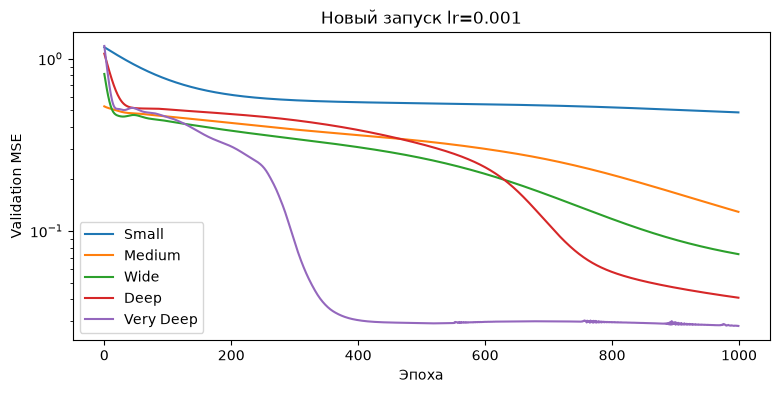

In [6]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)
x=torch.linspace(-3,3,200).reshape(-1,1)
y=torch.sin(3*x)+0.3*x+0.15*torch.randn_like(x)
indices=torch.randperm(200); tr,va=indices[:160],indices[160:]
architectures={"Small":[1,4,1],"Medium":[1,16,1],"Wide":[1,64,1],"Deep":[1,16,16,1],"Very Deep":[1,32,32,32,1]}
for lr in (0.01,0.001):
    print("Обучение lr =",lr)
    plt.figure(figsize=(9,4))
    for name,widths in architectures.items():
        torch.manual_seed(42)
        layers=[]
        for i in range(len(widths)-1):
            layers.append(nn.Linear(widths[i],widths[i+1]))
            if i<len(widths)-2: layers.append(nn.Tanh())
        model=nn.Sequential(*layers)
        optimizer=torch.optim.Adam(model.parameters(),lr=lr)
        history=[]
        for epoch in range(1000):
            optimizer.zero_grad(); loss=nn.functional.mse_loss(model(x[tr]),y[tr]); loss.backward(); optimizer.step()
            with torch.no_grad(): history.append(nn.functional.mse_loss(model(x[va]),y[va]).item())
        with torch.no_grad(): train=nn.functional.mse_loss(model(x[tr]),y[tr]).item()
        print(name,sum(p.numel() for p in model.parameters()),round(train,5),round(history[-1],5))
        plt.plot(history,label=name)
    plt.yscale('log'); plt.title(f'Обучение lr={lr}'); plt.xlabel('Эпоха'); plt.ylabel('Validation MSE'); plt.legend(); plt.show()
